## Figure 4
Top 15 Total deaths by ISO compared to FEWSNET brief

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import os
from datetime import datetime, UTC
from dotenv import find_dotenv, load_dotenv
import xarray as xr
import xvec

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
import cartopy.crs as ccrs

from utils import analysis_utils
from utils import isku_utils
from utils import plotting_utils
from utils import stats_utils

import importlib

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [3]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

In [15]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]
FC_PERIOD = slice("2026-10-01", "2027-03-31")

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=False,
    age_weight = True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [16]:
### Log baseline period and impact calculation
rate_l = "rate" if config.rate else "total"
baseline_tag = analysis_utils._baseline_tag(config.baseline_period)

In [17]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

In [18]:
# Aggregate Impact Regions to group_level
group_level = 'ISO' #IR: Impact region, # ADM1: State level, # ISO: Country level
impact, merge_key, base_cols = analysis_utils.aggregate_impact(impact, config, group_level)

In [9]:
def fetch_country_boundaries():
    url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
    return gpd.read_file(url)[["NAME", "ADM0_A3", "geometry"]]

def join_to_countries(gdf, countries):
    return gpd.sjoin(gdf.to_crs(countries.crs), countries, how="left", predicate="intersects")

countries = fetch_country_boundaries()

In [25]:
# Ordered by Population In Need (Projected March 2027)
df_fewsnet = ['Sudan', 'Pakistan', 'Nigeria', 'Dem. Rep. Congo', 
              'Yemen', 'Afghanistan', 'South Sudan',
              'Syria', 'Somalia', 'Colombia', 'Haiti',
              'Zimbabwe', 'Uganda', 'Kenya', 'Guatemala', 
              'Venezuela', 'Ukraine', 'Madagascar', 'Malawi',
              'Mozambique', 'Chad', 'Niger', 'Cameroon', 'Lebanon',
              'Angola', 'Sri Lanka', 'Burkina Faso', 'Nepal',
              'Central African Republic', 'Zambia', 'Mali', 'Burundi',
              'Honduras', 'Togo', 'Lesotho']

In [26]:
df = impact.mean(dim = config.dims).sum(dim = 'month').to_dataframe(name='impact').reset_index()
df = df.drop(columns = ['year'])
iso_to_name = countries.set_index("ADM0_A3")["NAME"].to_dict()
df["country"] = df["ISO"].map(iso_to_name)
# S. Sudan
df.loc[df['ISO'] == 'SSD', 'country'] = 'South Sudan'

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [27]:
rank_map = {country: i + 1 for i, country in enumerate(df_fewsnet)}
df["fewsnet_rank"] = df["country"].map(rank_map)

In [28]:
df.sort_values('impact', ascending = False).head(10).to_csv("impact_fewsnet_net.csv")

In [29]:
df.sort_values('impact', ascending = False).head(10)

,ISO,impact,country,fewsnet_rank
166,NGA,56099.353087,Nigeria,3.0
106,IND,55213.176774,India,NaN
104,IDN,29278.992211,Indonesia,NaN
32,BRA,19478.485184,Brazil,NaN
195,SDN,14659.333157,Sudan,1.0
222,THA,12181.571313,Thailand,NaN
220,TCD,11349.404042,Chad,21.0
48,COD,11265.684046,Dem. Rep. Congo,4.0
179,PHL,11070.826090,Philippines,NaN
164,NER,8415.471526,Niger,22.0


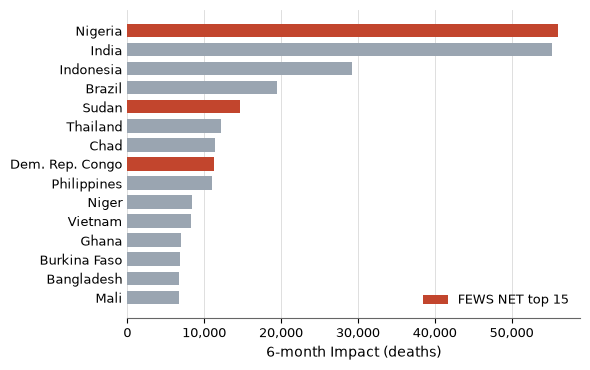

In [30]:
top = df.sort_values('impact', ascending=False).head(15)
y = np.arange(len(top))
in_top10 = (top['fewsnet_rank'] <= 15).values

highlight, base = '#C2452D', '#9AA5B1'  # still distinguishable in grayscale

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.barh(y[in_top10], top['impact'][in_top10], color=highlight, height=0.7,
        label='FEWS NET top 15')
ax.barh(y[~in_top10], top['impact'][~in_top10], color=base, height=0.7)

ax.set_yticks(y, top['country'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('6-month Impact (deaths)', fontsize=10)
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', length=0)

ax.grid(axis='x', color='0.85', lw=0.6)
ax.set_axisbelow(True)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('0.4')

ax.legend(frameon=False, fontsize=9, loc='lower right')
fig.tight_layout()
fig.savefig('top15_impact.png', dpi = 300, bbox_inches='tight')  # or .png with dpi=300